
# Homework 3 — exploratory data analysis

## 1. Dataset overview

In this notebook, I explore the training and test datasets for multilingual AI-generated text detection. The task is to distinguish between three classes: `human`, `ai`, and `fusion` (human-written text partially rewritten by an LLM).

My main objectives are to examine class distributions across languages and domains, analyze text lengths and writing characteristics, identify potential data quality issues, and use these findings to guide model selection and experimental design.

The competition is evaluated using macro-averaged F1, so I pay particular attention to class imbalance and the potentially challenging `fusion` category.

In [1]:
%pip -q install -U kaggle

import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("kaggle_token").strip()

print("Kaggle API token configured successfully.")

Kaggle API token configured successfully.


In [2]:
from pathlib import Path
import zipfile

COMPETITION = "ai-generated-text-detection-hw3-ucu-ai-2026"

DATA_DIR = Path("/content/hw3_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

!kaggle competitions download -c {COMPETITION} -p {DATA_DIR}

for archive_path in DATA_DIR.glob("*.zip"):
    with zipfile.ZipFile(archive_path, "r") as archive:
        archive.extractall(DATA_DIR)

print("\nDataset files:")
for path in sorted(DATA_DIR.glob("*.csv")):
    print(f"{path.name}: {path.stat().st_size / 1024**2:.1f} MB")

100% 380M/380M [00:04<00:00, 94.5MB/s]


Dataset files:
sample_submission.csv: 0.2 MB
test.csv: 79.6 MB
train.csv: 910.6 MB


In [3]:
import pandas as pd

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")

print("Train:", train_df.shape)
print("Test:", test_df.shape)
print("Submission:", sample_submission.shape)

print("\nColumns:", train_df.columns.tolist())
display(train_df.head(3))

Train: (272352, 5)
Test: (25000, 4)
Submission: (25000, 2)

Columns: ['id', 'text', 'lang', 'domain', 'label']


,id,text,lang,domain,label
0,e7adad,Diego's Demons Return: Is the Football Legend ...,en-EN,cnn_news,ai
1,3bab63,Herr Präsident! Meine Damen und Herren! Es wir...,de-DE,bundestag,human
2,4e6c1f,Frau Präsidentin! Liebe Kolleginnen und Kolleg...,de-DE,bundestag,human


In [17]:
import random
import numpy as np

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Random seed:", SEED)

Random seed: 42



## 2. Data quality and integrity

Before analyzing class distributions and linguistic characteristics, I examine the datasets for missing values, duplicate identifiers, duplicated texts, and unexpected categorical values.

These checks are especially important for this task because different versions of the same original text may share substantial content. Such similarities could cause data leakage if related texts are assigned to different training and validation folds.

I also verify that the test identifiers match the official submission template.

In [4]:
quality_summary = pd.DataFrame({
    "Dataset": ["Train", "Test"],
    "Rows": [len(train_df), len(test_df)],
    "Missing IDs": [
        train_df["id"].isna().sum(),
        test_df["id"].isna().sum()
    ],
    "Missing texts": [
        train_df["text"].isna().sum(),
        test_df["text"].isna().sum()
    ],
    "Duplicate IDs": [
        train_df["id"].duplicated().sum(),
        test_df["id"].duplicated().sum()
    ],
    "Duplicate texts": [
        train_df["text"].duplicated().sum(),
        test_df["text"].duplicated().sum()
    ]
})

display(quality_summary)

print("Missing values by column (train):")
display(train_df.isna().sum().to_frame("Missing count"))

print("\nUnique categorical values:")
for column in ["label", "lang", "domain"]:
    print(f"{column}: {sorted(train_df[column].dropna().unique().tolist())}")

print("\nTrain/test ID overlap:")
print(len(set(train_df["id"]) & set(test_df["id"])))

print("\nTest/submission ID consistency:")
print(
    set(test_df["id"]) == set(sample_submission["id"])
)

,Dataset,Rows,Missing IDs,Missing texts,Duplicate IDs,Duplicate texts
0,Train,272352,0,0,0,0
1,Test,25000,0,0,0,0


Missing values by column (train):


,Missing count
id,0
text,0
lang,0
domain,0
label,0



Unique categorical values:
label: ['ai', 'fusion', 'human']
lang: ['de-DE', 'en-EN']
domain: ['arxiv_papers', 'blog_authorship_corpus', 'bundestag', 'cnn_news', 'euro_court_cases', 'gutenberg', 'house_of_commons', 'student_essays']

Train/test ID overlap:
0

Test/submission ID consistency:
True


In [5]:
for name, df in [("Train", train_df), ("Test", test_df)]:
    text = df["text"].fillna("")

    empty_count = text.str.strip().eq("").sum()

    print(f"{name}:")
    print(f"  Empty or whitespace-only texts: {empty_count}")
    print(f"  Non-string text values: {df['text'].dropna().map(lambda x: not isinstance(x, str)).sum()}")

Train:
  Empty or whitespace-only texts: 0
  Non-string text values: 0
Test:
  Empty or whitespace-only texts: 0
  Non-string text values: 0



### Data quality findings

The dataset contains no missing values, empty texts, duplicate identifiers, or exact duplicate texts. The training data includes three valid labels, two languages, and eight domains.

The training and test sets have disjoint identifiers, and the test IDs match the official submission template.

No basic cleaning or row removal is necessary at this stage. However, the absence of exact duplicates does not rule out near-duplicates or related human/AI/fusion versions of the same source text. I will consider this risk when designing the validation strategy.


## 3. Class distribution

I first examine the distribution of the three target classes: `human`, `ai`, and `fusion`.

Although macro-F1 assigns equal importance to each class, class imbalance may influence model training and the quality of minority-class predictions. Understanding this distribution will help me decide whether class weighting, sampling, or decision-threshold adjustments should be investigated.

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
CLASS_COLORS = {
    "human": "#6C3CC8",
    "ai": "#E96BA8",
    "fusion": "#A991E8"
}

PALETTE = list(CLASS_COLORS.values())

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette=PALETTE,
    rc={
        "figure.figsize": (10, 5),
        "figure.dpi": 120,
        "axes.titlesize": 15,
        "axes.titleweight": "bold",
        "axes.labelsize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.alpha": 0.18,
        "grid.linestyle": "--",
        "font.family": "DejaVu Sans"
    }
)

In [8]:
class_order = ["human", "ai", "fusion"]

class_counts = (
    train_df["label"]
    .value_counts()
    .reindex(class_order, fill_value=0)
)

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": 100 * class_counts / len(train_df)
})

print("Overall class distribution:")
display(class_summary.round(2))

lang_class_counts = pd.crosstab(
    train_df["lang"], train_df["label"]
).reindex(columns=class_order, fill_value=0)

lang_class_percent = (
    lang_class_counts.div(
        lang_class_counts.sum(axis=1), axis=0
    ) * 100
)

print("\nClass distribution by language (counts):")
display(lang_class_counts)

print("\nClass distribution by language (%):")
display(lang_class_percent.round(2))

domain_class_counts = pd.crosstab(
    train_df["domain"], train_df["label"]
).reindex(columns=class_order, fill_value=0)

domain_class_percent = (
    domain_class_counts.div(
        domain_class_counts.sum(axis=1), axis=0
    ) * 100
)

print("\nClass distribution by domain (counts):")
display(domain_class_counts)

print("\nClass distribution by domain (%):")
display(domain_class_percent.round(2))

Overall class distribution:


,Count,Percentage (%)
label,,
human,66730,24.50
ai,121940,44.77
fusion,83682,30.73



Class distribution by language (counts):


label,human,ai,fusion
lang,,,
de-DE,14510,20337,17924
en-EN,52220,101603,65758



Class distribution by language (%):


label,human,ai,fusion
lang,,,
de-DE,27.50,38.54,33.97
en-EN,23.78,46.27,29.95



Class distribution by domain (counts):


label,human,ai,fusion
domain,,,
arxiv_papers,407,12050,1833
blog_authorship_corpus,12466,15684,12397
bundestag,14479,19977,17887
cnn_news,13395,19488,11402
euro_court_cases,6277,11141,10160
gutenberg,247,6719,378
house_of_commons,6953,15298,9608
student_essays,12506,21583,20017



Class distribution by domain (%):


label,human,ai,fusion
domain,,,
arxiv_papers,2.85,84.32,12.83
blog_authorship_corpus,30.74,38.68,30.57
bundestag,27.66,38.17,34.17
cnn_news,30.25,44.01,25.75
euro_court_cases,22.76,40.40,36.84
gutenberg,3.36,91.49,5.15
house_of_commons,21.82,48.02,30.16
student_essays,23.11,39.89,37.00


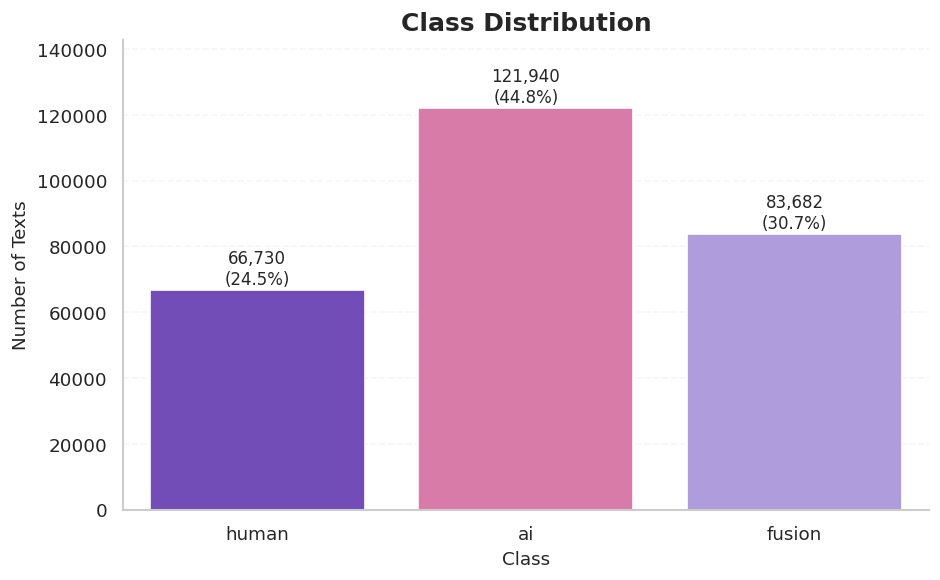

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    hue=class_counts.index,
    palette=CLASS_COLORS,
    legend=False,
    ax=ax
)

for i, count in enumerate(class_counts.values):
    ax.text(
        i,
        count + class_counts.max() * 0.015,
        f"{count:,}\n({100 * count / len(train_df):.1f}%)",
        ha="center",
        fontsize=10,
        fontweight="medium"
    )

ax.set(
    title="Class Distribution",
    xlabel="Class",
    ylabel="Number of Texts"
)

ax.set_ylim(0, class_counts.max() * 1.17)
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

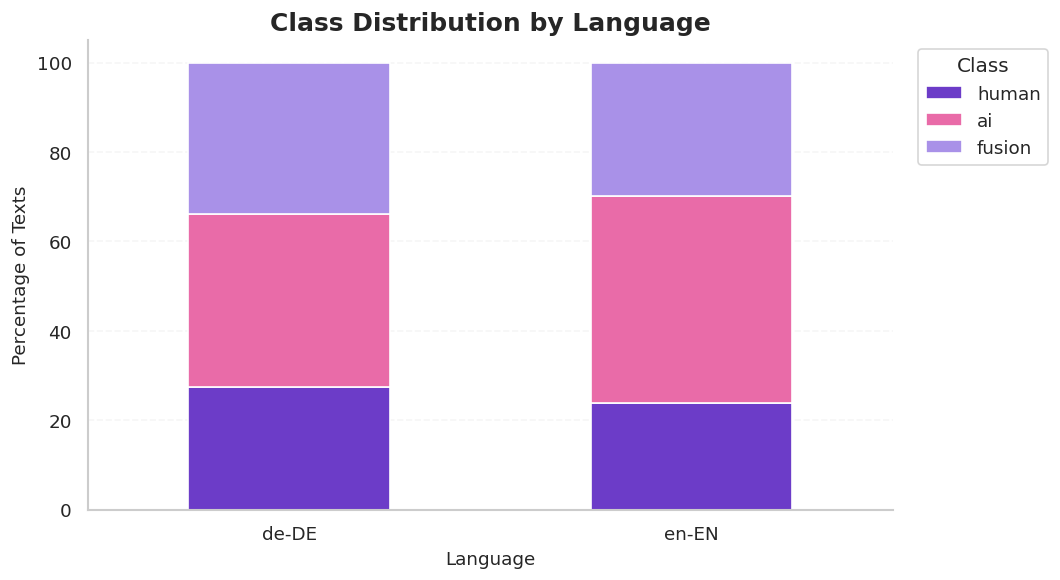

In [10]:
ax = lang_class_percent[class_order].plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=PALETTE,
    edgecolor="white",
    linewidth=1
)

ax.set(
    title="Class Distribution by Language",
    xlabel="Language",
    ylabel="Percentage of Texts"
)

ax.tick_params(axis="x", rotation=0)
ax.legend(title="Class", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

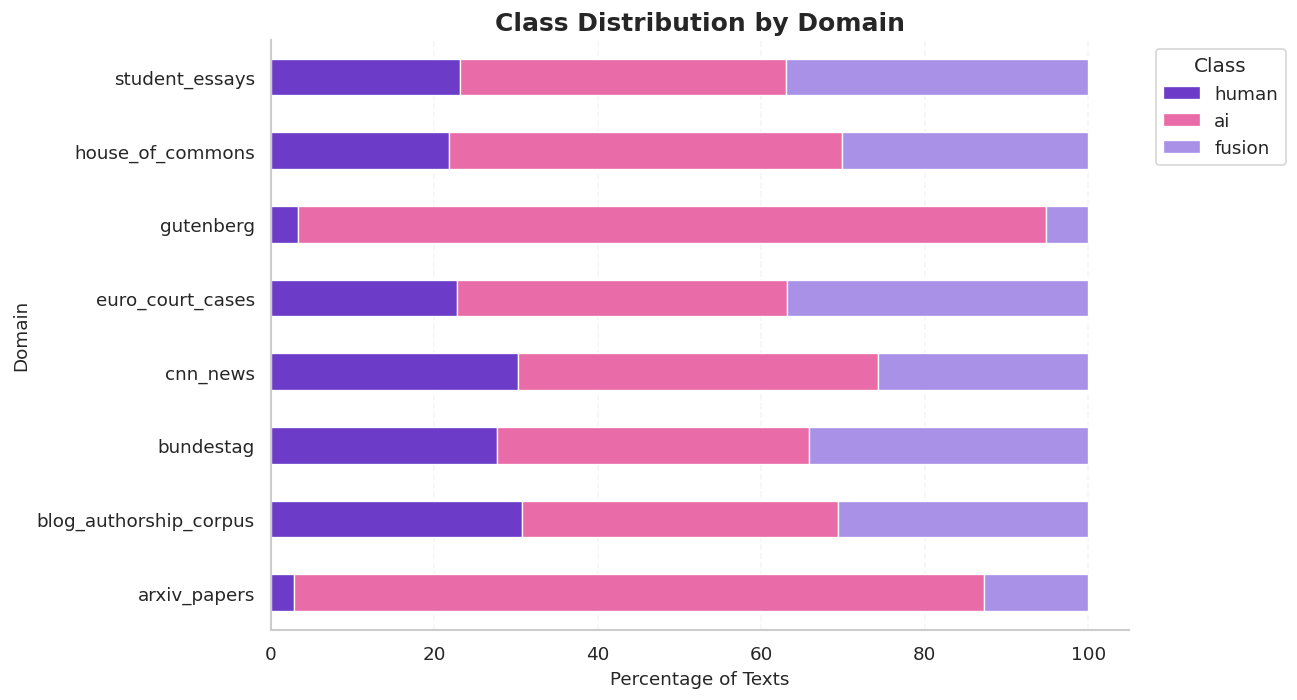

In [11]:
ax = domain_class_percent[class_order].plot(
    kind="barh",
    stacked=True,
    figsize=(11, 6),
    color=PALETTE,
    edgecolor="white",
    linewidth=0.8
)

ax.set(
    title="Class Distribution by Domain",
    xlabel="Percentage of Texts",
    ylabel="Domain"
)

ax.legend(title="Class", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()


### Class distribution findings

The dataset is moderately imbalanced: `ai` accounts for 44.77% of training examples, followed by `fusion` (30.73%) and `human` (24.50%).

The class proportions also vary across languages and domains. In particular, `ai` represents 84.32% of `arxiv_papers` and 91.49% of `gutenberg`, whereas the class distributions are substantially more balanced in domains such as `bundestag` and `student_essays`.

These differences suggest that models may exploit domain-specific class priors rather than learning only authorship-related characteristics. I will therefore evaluate performance by language and domain, investigate class weighting, and compare models with and without explicit domain information.

Because the evaluation metric is macro-F1, I will pay attention to per-class precision and recall rather than relying on overall accuracy.


## 4. Text length analysis

I analyze text lengths in characters and words to understand the variability of the dataset and identify potential challenges for transformer-based models.

In particular, I compare text lengths across classes, languages, and domains. These findings will help me decide whether standard truncation is sufficient or whether longer texts require chunking or alternative aggregation strategies.

In [12]:
for df in [train_df, test_df]:
    df["char_count"] = df["text"].str.len()
    df["word_count"] = df["text"].str.split().str.len()

print("Overall text length statistics (train):")

display(
    train_df[["char_count", "word_count"]]
    .describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
    .round(1)
)

print("\nText length statistics by class:")

length_by_class = (
    train_df.groupby("label")[["char_count", "word_count"]]
    .agg(["mean", "median", "std", "min", "max"])
    .reindex(class_order)
)

display(length_by_class.round(1))

Overall text length statistics (train):


,char_count,word_count
count,272352.0,272352.0
mean,3444.1,542.3
std,2679.7,426.7
min,76.0,20.0
10%,748.0,126.0
25%,1631.0,273.0
50%,2977.0,463.0
75%,4487.0,686.0
90%,6318.0,974.0
95%,8074.0,1263.0



Text length statistics by class:


char_count                            word_count                    \
             mean  median     std min    max       mean median    std min   
label                                                                       
human      3492.1  2909.0  2876.7  76  21376      577.9  481.0  473.4  20   
ai         3285.8  3112.0  2030.7  87  22646      493.5  465.0  294.3  20   
fusion     3636.5  2778.0  3269.0  92  34876      585.2  445.0  530.5  20   

              
         max  
label         
human   2998  
ai      2996  
fusion  3000

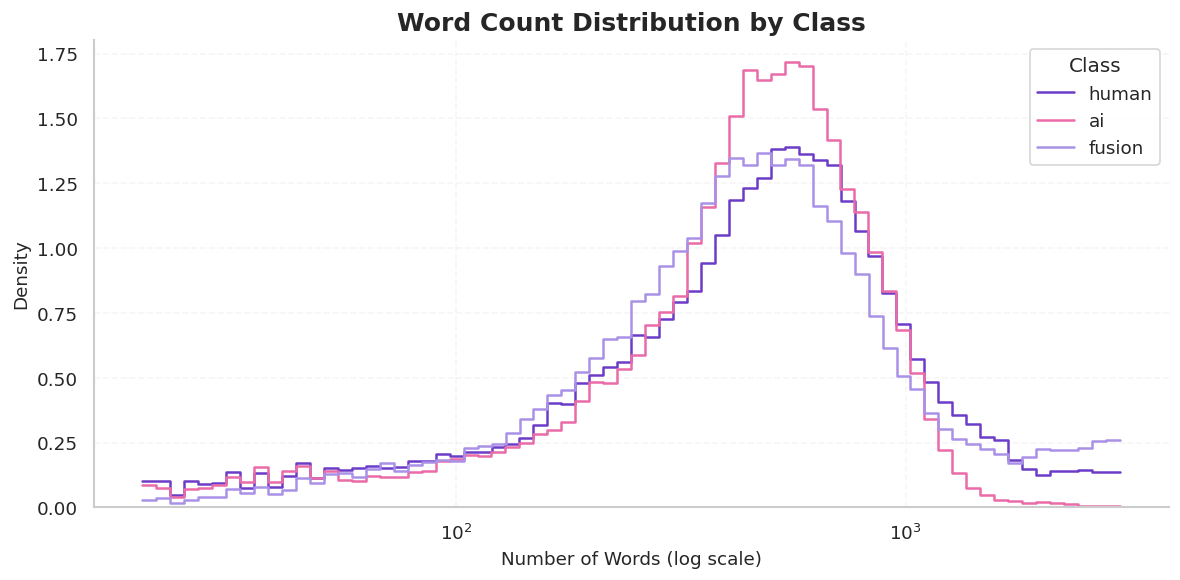

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))

for label in class_order:
    values = train_df.loc[
        train_df["label"] == label, "word_count"
    ]

    sns.histplot(
        values,
        bins=70,
        stat="density",
        element="step",
        fill=False,
        log_scale=True,
        color=CLASS_COLORS[label],
        label=label,
        ax=ax
    )

ax.set(
    title="Word Count Distribution by Class",
    xlabel="Number of Words (log scale)",
    ylabel="Density"
)

ax.legend(title="Class")
plt.tight_layout()
plt.show()

Word counts by language:


,count,mean,median,std
lang,,,,
de-DE,52771,534.9,512.0,263.4
en-EN,219581,544.1,444.0,457.4



Word counts by domain:


,count,mean,median,std
domain,,,,
arxiv_papers,14290,1034.6,888.0,647.3
gutenberg,7344,800.3,706.0,462.2
euro_court_cases,27578,822.0,633.0,613.2
cnn_news,44285,598.5,548.0,286.3
house_of_commons,31859,641.8,540.0,511.6
bundestag,52343,534.9,512.0,261.4
student_essays,54106,390.0,363.0,170.7
blog_authorship_corpus,40547,205.3,131.0,229.2


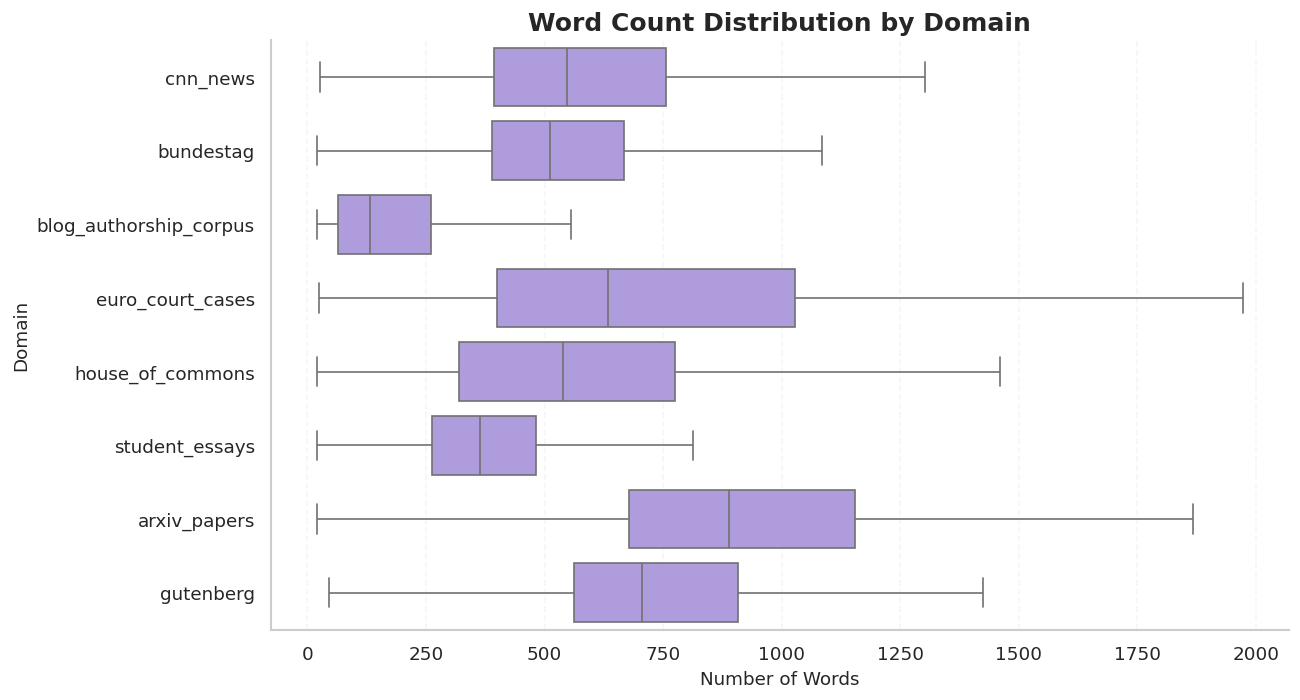

In [14]:
print("Word counts by language:")
display(
    train_df.groupby("lang")["word_count"]
    .agg(["count", "mean", "median", "std"])
    .round(1)
)

print("\nWord counts by domain:")
display(
    train_df.groupby("domain")["word_count"]
    .agg(["count", "mean", "median", "std"])
    .sort_values("median", ascending=False)
    .round(1)
)

fig, ax = plt.subplots(figsize=(11, 6))

sns.boxplot(
    data=train_df,
    x="word_count",
    y="domain",
    color="#A991E8",
    showfliers=False,
    ax=ax
)

ax.set(
    title="Word Count Distribution by Domain",
    xlabel="Number of Words",
    ylabel="Domain"
)

plt.tight_layout()
plt.show()


### Text length findings

The median text length is 463 words, with a 95th percentile of 1,263 words and a maximum of 3,000 words. This indicates substantial variability in document lengths.

Text length distributions differ across classes. The `fusion` class has the highest standard deviation (530.5 words), whereas `ai` texts have a more concentrated distribution (294.3 words).

Domain differences are also pronounced: `arxiv_papers` has a median of 888 words, compared with only 131 words for `blog_authorship_corpus`. Therefore, text length may be associated with both domain and class.

These results motivate experiments with different context lengths and long-document handling strategies. In particular, I will investigate whether truncation, head-tail selection, or chunk-based aggregation provides the best validation macro-F1.


### Train–test text length comparison

I compare text lengths between the training and test datasets to identify potential distribution shifts. Since test labels are unavailable, this analysis focuses only on descriptive properties and does not use test data to fit preprocessing or model components.

,Train,Test
count,272352.0,25000.0
mean,542.3,518.5
std,426.7,406.6
min,20.0,20.0
25%,273.0,239.0
50%,463.0,458.0
75%,686.0,683.0
90%,974.0,951.0
95%,1263.0,1177.0
99%,2450.0,2278.0


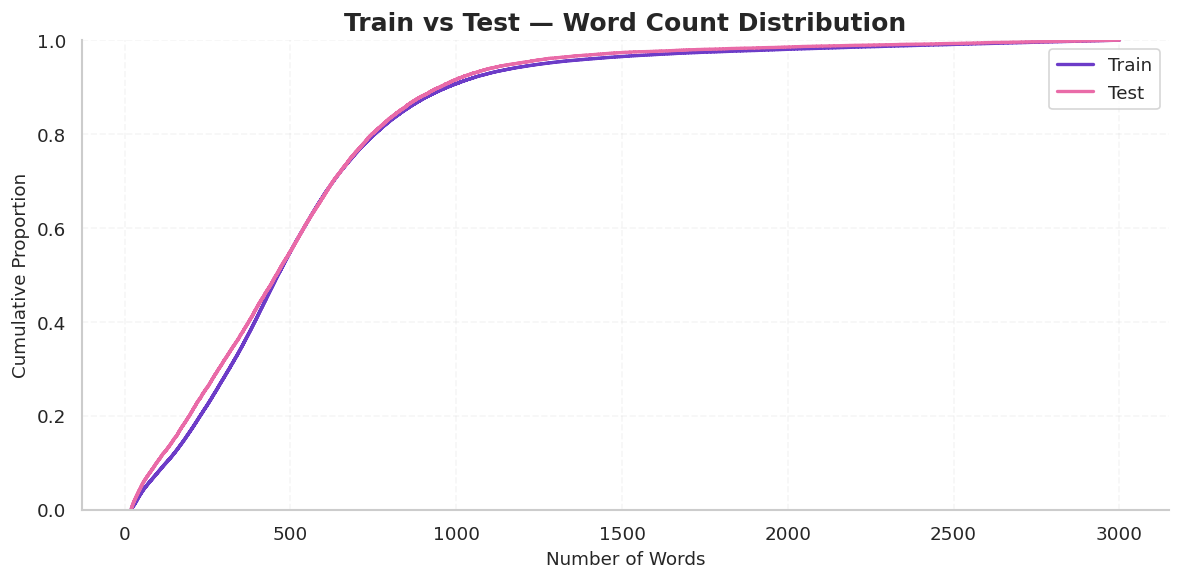

In [15]:
length_comparison = pd.DataFrame({
    "Train": train_df["word_count"].describe(
        percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
    ),
    "Test": test_df["word_count"].describe(
        percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
    )
})

display(length_comparison.round(1))

fig, ax = plt.subplots(figsize=(10, 5))

for name, df, color in [
    ("Train", train_df, "#6C3CC8"),
    ("Test", test_df, "#E96BA8")
]:
    sns.ecdfplot(
        data=df,
        x="word_count",
        label=name,
        color=color,
        linewidth=2,
        ax=ax
    )

ax.set(
    title="Train vs Test — Word Count Distribution",
    xlabel="Number of Words",
    ylabel="Cumulative Proportion"
)

ax.legend()
plt.tight_layout()
plt.show()


### Train–test comparison findings

The training and test datasets have broadly similar word-count distributions, with median lengths of 463 and 458 words, respectively.

The training set contains a slightly heavier tail of long documents, as reflected by its higher 95th and 99th percentiles.

These observations suggest that text length distributions are reasonably consistent across the two datasets. However, similar length distributions do not guarantee identical class distributions or model performance.


### Transformer token length analysis

Word counts do not directly correspond to transformer token counts because multilingual tokenizers split text into subword units.

I use the pretrained XLM-RoBERTa tokenizer to estimate tokenized sequence lengths on a reproducible stratified sample of 10,000 training texts.

I then measure the proportion of documents exceeding common sequence-length limits and compare these proportions across classes and languages. This analysis will guide the selection of `max_length` and motivate possible long-text handling experiments.

In [18]:
%pip -q install transformers sentencepiece

from transformers import AutoTokenizer
from sklearn.model_selection import train_test_split

TOKENIZER_NAME = "FacebookAI/xlm-roberta-base"

tokenizer = AutoTokenizer.from_pretrained(
    TOKENIZER_NAME,
    use_fast=True
)

_, token_sample = train_test_split(
    train_df,
    test_size=10000,
    stratify=train_df["label"],
    random_state=SEED
)

token_sample = token_sample.copy()

batch_size = 128
token_lengths = []

texts = token_sample["text"].tolist()

for start in range(0, len(texts), batch_size):
    batch = texts[start:start + batch_size]

    encoded = tokenizer(
        batch,
        add_special_tokens=True,
        truncation=False,
        padding=False,
        return_attention_mask=False
    )

    token_lengths.extend(
        len(ids) for ids in encoded["input_ids"]
    )

token_sample["token_count"] = token_lengths

print("Token length statistics:")
display(
    token_sample["token_count"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
    .round(1)
)

print("\nProportion exceeding token limits:")
for limit in [128, 256, 512, 1024, 2048]:
    percentage = 100 * (token_sample["token_count"] > limit).mean()
    print(f">{limit:4d} tokens: {percentage:.2f}%")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1007 > 512). Running this sequence through the model will result in indexing errors


Token length statistics:


,token_count
count,10000.0
mean,792.2
std,655.4
min,26.0
25%,382.0
50%,665.0
75%,1004.0
90%,1440.0
95%,1860.0
99%,3610.0



Proportion exceeding token limits:
> 128 tokens: 93.58%
> 256 tokens: 85.26%
> 512 tokens: 64.13%
>1024 tokens: 23.86%
>2048 tokens: 3.94%


Token limit,128,256,512,1024,2048
Class,,,,,
ai,93.54,87.51,68.60,22.96,1.14
fusion,94.37,83.83,60.17,23.43,7.13
human,92.65,82.94,60.94,26.04,5.06


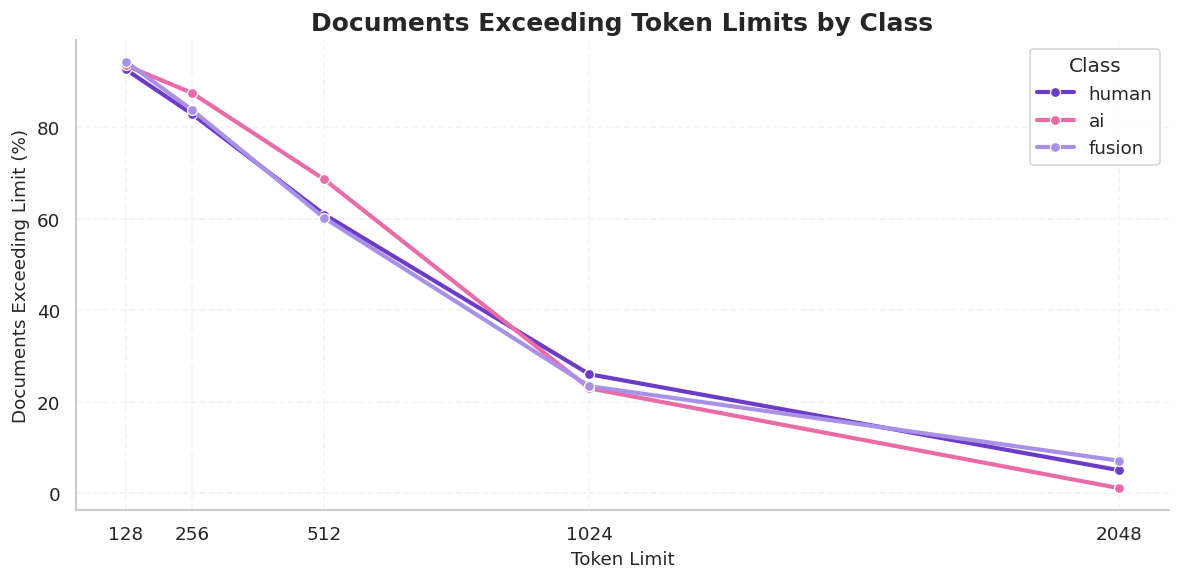


Token lengths by language:


,count,mean,median,std
lang,,,,
de-DE,1936,800.8,763.5,373.7
en-EN,8064,790.2,620.0,706.5


In [19]:
limits = [128, 256, 512, 1024, 2048]

records = []

for label in class_order:
    subset = token_sample[token_sample["label"] == label]

    for limit in limits:
        records.append({
            "Class": label,
            "Token limit": limit,
            "Exceeding (%)": 100 * (subset["token_count"] > limit).mean()
        })

token_limit_df = pd.DataFrame(records)

display(
    token_limit_df.pivot(
        index="Class",
        columns="Token limit",
        values="Exceeding (%)"
    ).round(2)
)

fig, ax = plt.subplots(figsize=(10, 5))

sns.lineplot(
    data=token_limit_df,
    x="Token limit",
    y="Exceeding (%)",
    hue="Class",
    hue_order=class_order,
    palette=CLASS_COLORS,
    marker="o",
    linewidth=2.5,
    ax=ax
)

ax.set(
    title="Documents Exceeding Token Limits by Class",
    xlabel="Token Limit",
    ylabel="Documents Exceeding Limit (%)"
)

ax.set_xticks(limits)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

print("\nToken lengths by language:")
display(
    token_sample.groupby("lang")["token_count"]
    .agg(["count", "mean", "median", "std"])
    .round(1)
)


### Transformer token length findings

Using a stratified sample of 10,000 training documents, I found that the median XLM-RoBERTa sequence length is 665 tokens, while 64.13% of documents exceed 512 tokens and 23.86% exceed 1024 tokens.

The proportion of documents exceeding 512 tokens is highest for `ai` (68.60%). However, `fusion` has the largest proportion of very long documents, with 7.13% exceeding 2048 tokens, compared with only 1.14% for `ai`.

Token lengths also differ by language: the median is 763.5 for German and 620 for English.

These findings suggest that standard 512-token truncation discards substantial portions of many documents. I will therefore compare standard truncation against alternative strategies such as head-tail selection and chunk-based aggregation, using the same validation split and macro-F1 metric.


## 5. Qualitative analysis of text classes

I inspect representative examples of `human`, `ai`, and `fusion` texts to explore potential differences in writing style, structure, and consistency.

To reduce confounding effects, I compare examples within the same language and domain. I focus particularly on the `fusion` class, where human-written and AI-rewritten content may exhibit different stylistic characteristics within the same document.

These observations are exploratory hypotheses rather than definitive indicators of AI-generated text.

In [20]:
EXAMPLE_LANG = "en-EN"
EXAMPLE_DOMAIN = "student_essays"
EXAMPLES_PER_CLASS = 2

example_pool = train_df[
    (train_df["lang"] == EXAMPLE_LANG) &
    (train_df["domain"] == EXAMPLE_DOMAIN)
]

print("Available examples by class:")
display(example_pool["label"].value_counts().reindex(class_order))

examples = (
    example_pool.groupby("label", group_keys=False)
    .sample(n=EXAMPLES_PER_CLASS, random_state=SEED)
)

for label in class_order:
    subset = examples[examples["label"] == label]

    print(f"\n{'=' * 65}")
    print(f"CLASS: {label.upper()}")
    print(f"{'=' * 65}")

    for _, row in subset.iterrows():
        print(f"\nID: {row['id']}")
        print(f"Words: {row['word_count']}")
        print(f"Text preview:\n{row['text'][:1200]}...")
        print("-" * 65)

Available examples by class:


,count
label,
human,12506
ai,21583
fusion,20017



CLASS: HUMAN

ID: 93fc43
Words: 363
Text preview:
Research has shown that exercising does help you live longer. However what if you were forced to do a sport or something after school that is not a sport? Me personally I disagree, but I am going to talk about my opinions on why right now. People shouldn't have to do anything after school if they don't want to. Staying after school is a opportunity to have fun and see some of your friends. Therefore if it was forced it would defiantly not be as much fun because you wouldn't want to do it. Nobody should be forced to do something if they don't want to. There are other things people want or have to do sometimes instead of staying after school everyday. It would take away some of the fun. For instance what if someone wants to go out of town but they can't because they have to stay after school. Additionally people have other things to do outside of school, things like ballet, basketball for someplace else, maybe any sport, etc.. If they di


### Qualitative analysis methodology

I selected two examples per class from English student essays to compare texts within the same language and domain.

This controlled selection reduces differences caused by language and genre. I will use the examples to investigate potential stylistic characteristics of the three classes, particularly whether `fusion` texts exhibit greater variation within individual documents.

Because a small number of examples cannot establish reliable class-level patterns, I will complement this inspection with quantitative stylometric analysis across the training dataset.


### Stylometric feature analysis

I investigate stylometric characteristics that may help distinguish human-written, AI-generated, and partially AI-rewritten texts.

I focus on sentence length, sentence-length variability, lexical diversity, and punctuation usage. These features may capture differences in writing consistency and editing patterns.

To reduce the influence of domain and language, I initially compare texts within English student essays before considering broader dataset-level patterns.

In [21]:
import re
import numpy as np
import pandas as pd

def extract_stylometric_features(text):
    words = re.findall(r"\b\w+\b", text.lower())
    sentences = [
        s.strip()
        for s in re.split(r"(?<=[.!?])\s+", text)
        if s.strip()
    ]

    word_count = len(words)
    sentence_lengths = [
        len(re.findall(r"\b\w+\b", s))
        for s in sentences
    ]

    return {
        "avg_sentence_length": (
            np.mean(sentence_lengths) if sentence_lengths else 0
        ),
        "std_sentence_length": (
            np.std(sentence_lengths) if len(sentence_lengths) > 1 else 0
        ),
        "lexical_diversity": (
            len(set(words)) / word_count if word_count else 0
        ),
        "comma_rate": text.count(",") / max(word_count, 1) * 100,
        "question_rate": text.count("?") / max(word_count, 1) * 100,
        "exclamation_rate": text.count("!") / max(word_count, 1) * 100,
    }

stylometry_df = example_pool[
    ["id", "label", "lang", "domain", "text"]
].copy()

features = pd.DataFrame(
    stylometry_df["text"]
    .map(extract_stylometric_features)
    .tolist(),
    index=stylometry_df.index
)

stylometry_df = pd.concat(
    [stylometry_df, features],
    axis=1
)

print("Stylometric dataset:", stylometry_df.shape)
display(stylometry_df.drop(columns="text").head())

Stylometric dataset: (54106, 11)


,id,label,lang,domain,avg_sentence_length,std_sentence_length,lexical_diversity,comma_rate,question_rate,exclamation_rate
6,a6f4c8,human,en-EN,student_essays,22.941176,10.701680,0.394872,1.282051,0.000000,0.256410
19,18b6c4,ai,en-EN,student_essays,24.571429,11.914663,0.550388,6.007752,0.000000,0.000000
24,6d49dc,fusion,en-EN,student_essays,30.916667,15.085635,0.495957,3.504043,0.000000,0.000000
27,863926,ai,en-EN,student_essays,12.785714,6.773674,0.439479,6.145251,2.048417,0.744879
40,7eb0fd,fusion,en-EN,student_essays,36.000000,27.531800,0.409722,4.398148,0.000000,0.231481


In [22]:
feature_columns = [
    "avg_sentence_length",
    "std_sentence_length",
    "lexical_diversity",
    "comma_rate",
    "question_rate",
    "exclamation_rate"
]

stylometry_summary = (
    stylometry_df
    .groupby("label")[feature_columns]
    .agg(["mean", "median", "std"])
    .reindex(class_order)
)

display(stylometry_summary.round(3))

avg_sentence_length                 std_sentence_length                \
                      mean  median     std                mean median    std   
label                                                                          
human               23.078  20.531  16.152              10.753  9.208  6.604   
ai                  17.086  15.875  13.101               7.015  6.680  2.133   
fusion              20.736  19.833   5.670               9.438  8.162  5.200   

       lexical_diversity               comma_rate               question_rate  \
                    mean median    std       mean median    std          mean   
label                                                                           
human              0.436  0.435  0.085      3.221  3.038  1.992         0.174   
ai                 0.561  0.558  0.072      5.788  5.765  1.635         0.934   
fusion             0.525  0.520  0.092      4.103  4.030  1.735         0.166   

                     exclamation_rate                
       median    std             mean median    std  
label                                                
human   0.000  0.345            0.067  0.000  0.292  
ai      0.703  0.952            0.643  0.355  0.839  
fusion  0.000  0.354            0.064  0.000  0.251

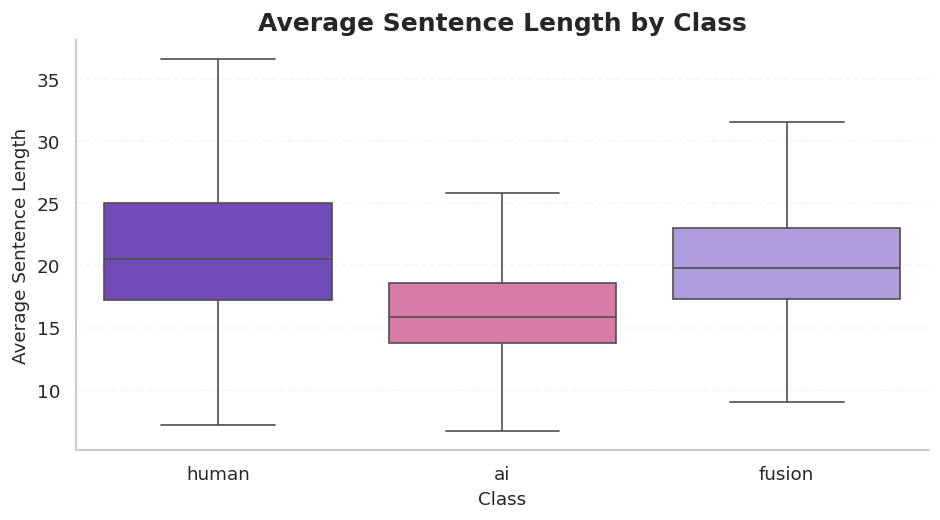

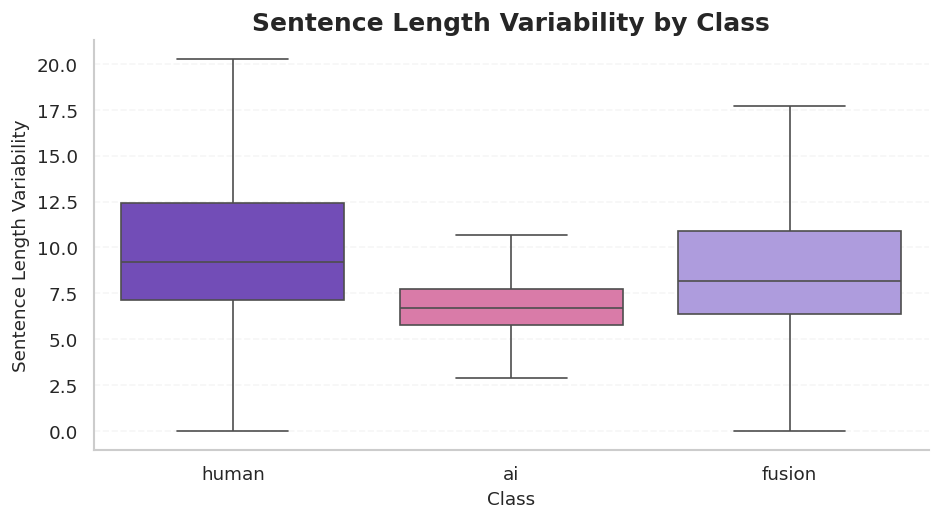

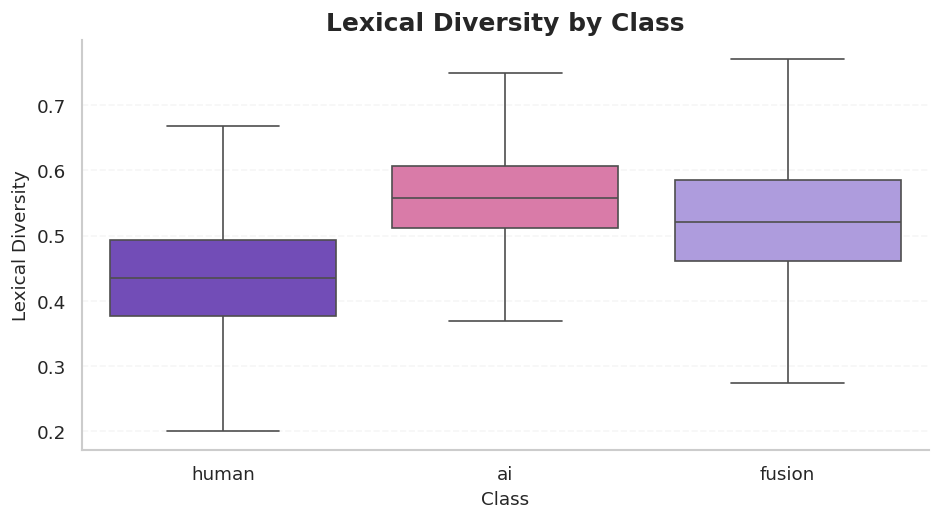

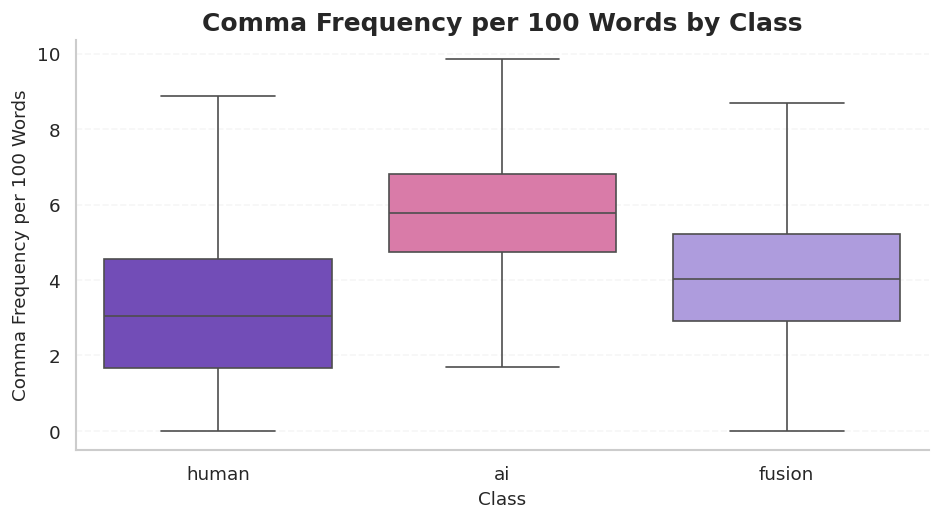

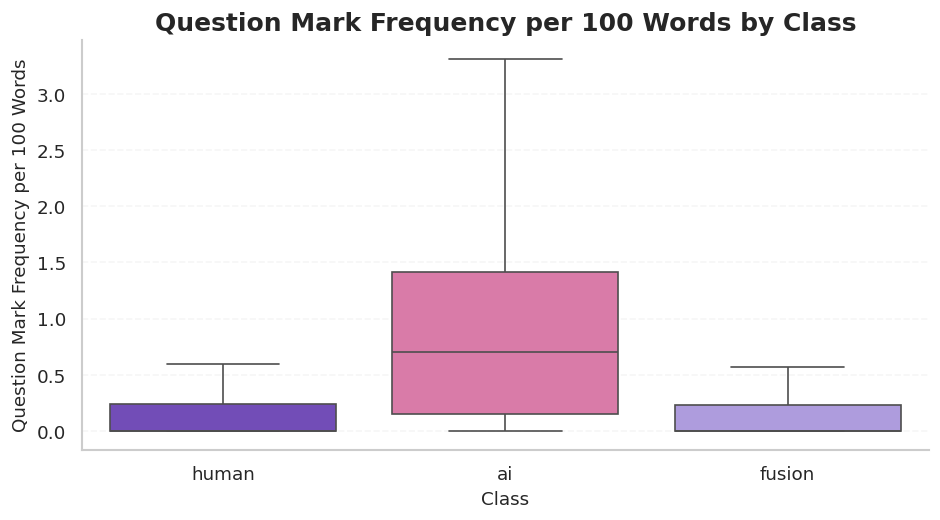

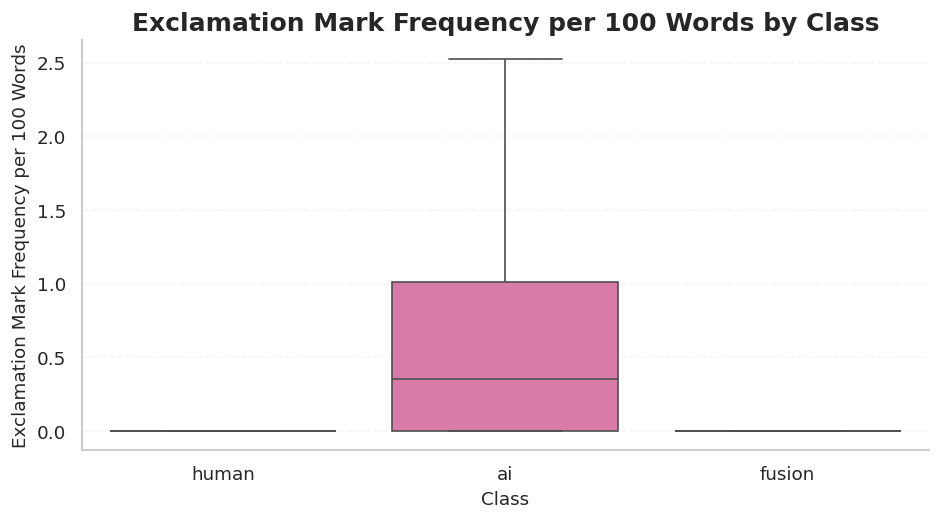

In [23]:
feature_titles = {
    "avg_sentence_length": "Average Sentence Length",
    "std_sentence_length": "Sentence Length Variability",
    "lexical_diversity": "Lexical Diversity",
    "comma_rate": "Comma Frequency per 100 Words",
    "question_rate": "Question Mark Frequency per 100 Words",
    "exclamation_rate": "Exclamation Mark Frequency per 100 Words"
}

for feature in feature_columns:
    fig, ax = plt.subplots(figsize=(8, 4.5))

    sns.boxplot(
        data=stylometry_df,
        x="label",
        y=feature,
        order=class_order,
        hue="label",
        palette=CLASS_COLORS,
        showfliers=False,
        legend=False,
        ax=ax
    )

    ax.set(
        title=f"{feature_titles[feature]} by Class",
        xlabel="Class",
        ylabel=feature_titles[feature]
    )

    plt.tight_layout()
    plt.show()


### Stylometric analysis findings

Within English student essays, the three classes exhibit noticeable stylometric differences.

AI-generated texts have shorter and more consistent sentences on average (17.09 words per sentence, with a mean sentence-length standard deviation of 7.02), compared with human-written texts (23.08 and 10.75, respectively).

Lexical diversity and punctuation usage also differ substantially. AI-generated essays have a higher average type-token ratio (0.561) and more frequent commas, question marks, and exclamation marks. Fusion texts often exhibit intermediate values, suggesting that combining lexical and structural features may help distinguish partially rewritten content.

However, these patterns are domain-specific, and lexical diversity is sensitive to document length. I will investigate whether the observed differences persist across other domains before incorporating stylometric features into the classification pipeline.


### Cross-domain stylometric consistency

To determine whether the observed stylometric patterns generalize beyond student essays, I compare the same features across different domains.

I use a reproducible sample from each domain and class to avoid allowing larger class-domain groups to dominate the analysis. I focus on median values and examine whether the relative differences between `human`, `ai`, and `fusion` remain consistent.

/tmp/ipykernel_3939/1355372584.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(n=min(500, len(g)), random_state=SEED))



avg_sentence_length


label,human,ai,fusion
domain,,,
arxiv_papers,14.932,19.609,19.991
blog_authorship_corpus,14.911,14.200,14.357
bundestag,15.383,16.863,15.703
cnn_news,20.039,22.496,17.990
euro_court_cases,15.604,17.850,15.514
gutenberg,17.667,20.839,17.026
house_of_commons,19.294,20.148,19.359
student_essays,21.050,15.860,20.229


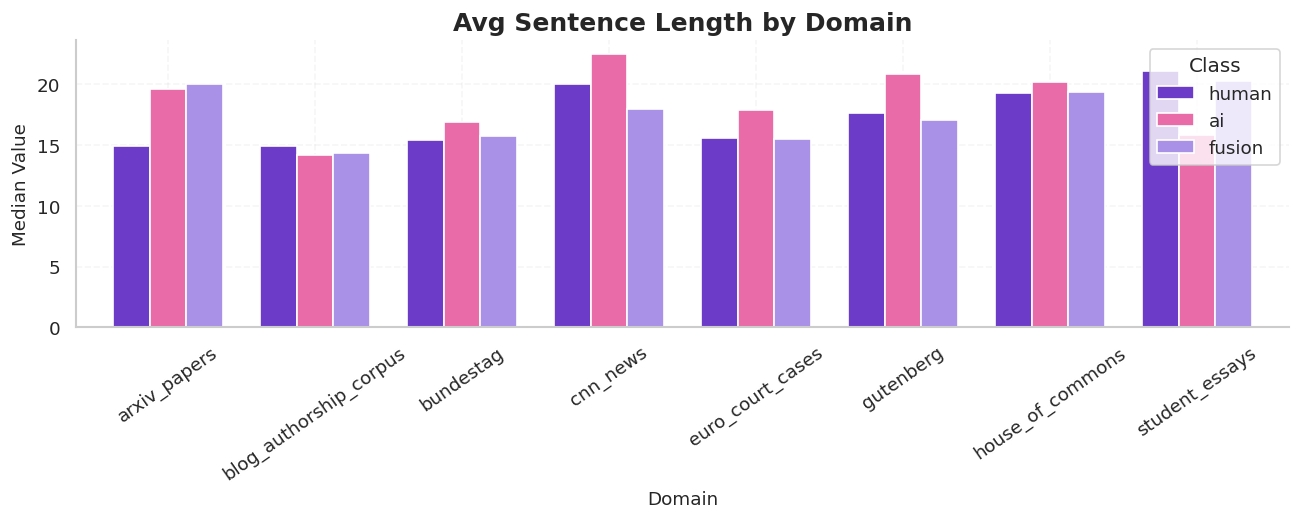


lexical_diversity


label,human,ai,fusion
domain,,,
arxiv_papers,0.302,0.402,0.306
blog_authorship_corpus,0.667,0.751,0.713
bundestag,0.535,0.570,0.532
cnn_news,0.465,0.538,0.512
euro_court_cases,0.341,0.463,0.383
gutenberg,0.427,0.523,0.416
house_of_commons,0.443,0.519,0.480
student_essays,0.433,0.557,0.514


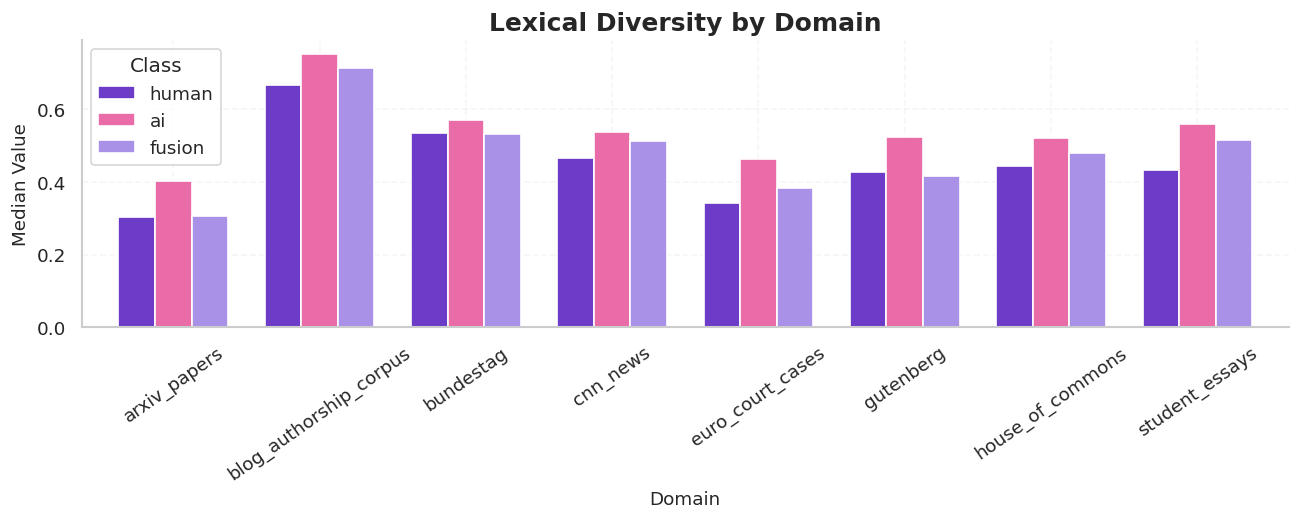


comma_rate


label,human,ai,fusion
domain,,,
arxiv_papers,7.087,4.717,5.667
blog_authorship_corpus,4.000,5.549,4.036
bundestag,7.340,7.548,7.438
cnn_news,4.563,5.812,4.635
euro_court_cases,3.203,5.475,3.645
gutenberg,7.471,7.282,7.273
house_of_commons,4.176,5.094,4.089
student_essays,2.973,5.726,3.941


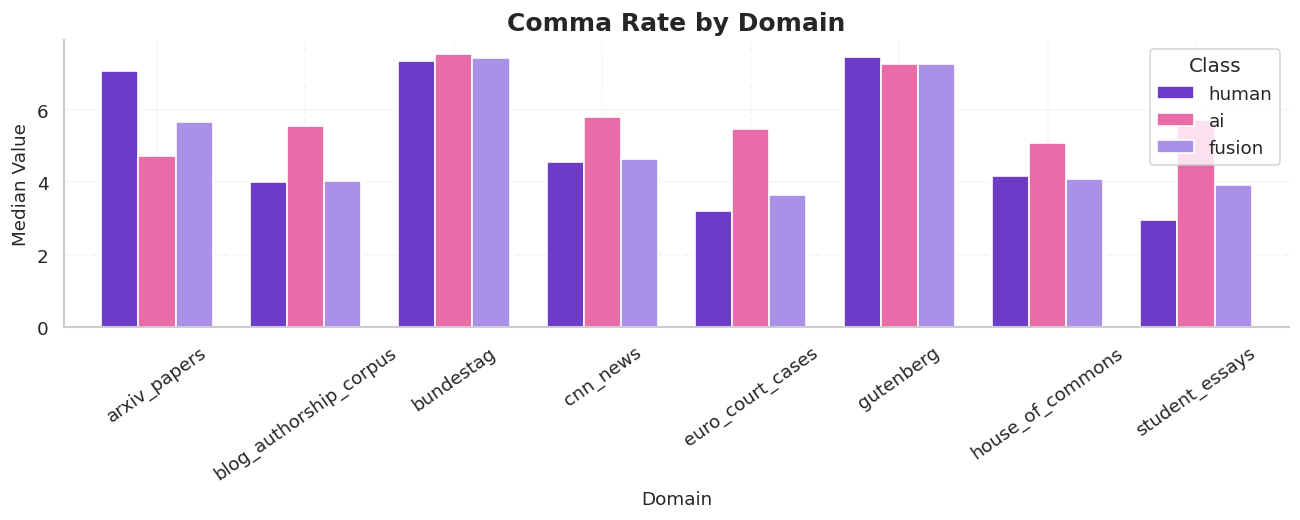

In [24]:
domain_sample = (
    train_df.groupby(["domain", "label"], group_keys=False)
    .sample(
        n=500,
        random_state=SEED,
        replace=False
    )
    if train_df.groupby(["domain", "label"]).size().min() >= 500
    else train_df.groupby(["domain", "label"], group_keys=False)
    .apply(lambda g: g.sample(n=min(500, len(g)), random_state=SEED))
    .reset_index(drop=True)
)

domain_features = pd.DataFrame(
    domain_sample["text"]
    .map(extract_stylometric_features)
    .tolist(),
    index=domain_sample.index
)

domain_stylometry = pd.concat(
    [
        domain_sample[["domain", "lang", "label"]].copy(),
        domain_features
    ],
    axis=1
)

for feature in [
    "avg_sentence_length",
    "lexical_diversity",
    "comma_rate"
]:
    comparison = domain_stylometry.pivot_table(
        index="domain",
        columns="label",
        values=feature,
        aggfunc="median"
    ).reindex(columns=class_order)

    print(f"\n{feature}")
    display(comparison.round(3))

    ax = comparison.plot(
        kind="bar",
        figsize=(11, 4.5),
        color=PALETTE,
        width=0.75
    )

    ax.set(
        title=f"{feature.replace('_', ' ').title()} by Domain",
        xlabel="Domain",
        ylabel="Median Value"
    )

    ax.tick_params(axis="x", rotation=35)
    ax.legend(title="Class")
    plt.tight_layout()
    plt.show()


### Cross-domain stylometric findings

The cross-domain analysis reveals that stylometric differences between classes are not entirely consistent across domains.

AI-generated texts exhibit higher median lexical diversity than human-written texts in all eight domains. However, sentence-length patterns vary considerably. In student essays, human texts contain longer sentences, whereas the opposite pattern appears in scientific papers.

Punctuation patterns are also domain-dependent. These findings suggest that stylometric features may provide useful complementary information, but their predictive value should be evaluated across different domains rather than assumed to generalize universally.

I will consider stylometric features as a potential addition to the classical baseline and evaluate their contribution using a fixed validation strategy.


## 6. Near-duplicate detection and validation strategy

The dataset may contain multiple versions derived from the same original text. Although the competition organizers keep related versions together in the official train/test split, a random internal split could separate them and introduce information leakage.

I investigate exact and approximate text similarity before defining the validation strategy. My goal is to estimate the risk of related documents appearing in both training and validation sets and determine whether group-aware splitting is necessary.

In [25]:
import hashlib
import re

def normalize_for_fingerprint(text):
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"[^\w\s]", "", text)
    return text.strip()

fingerprints = train_df["text"].map(
    lambda text: hashlib.md5(
        normalize_for_fingerprint(text)[:500].encode("utf-8")
    ).hexdigest()
)

fingerprint_counts = fingerprints.value_counts()

print("Total documents:", len(train_df))
print("Unique fingerprints:", fingerprints.nunique())
print("Repeated fingerprints:", (fingerprint_counts > 1).sum())
print(
    "Documents sharing a fingerprint:",
    fingerprints.isin(fingerprint_counts[fingerprint_counts > 1].index).sum()
)

duplicate_groups = train_df.loc[
    fingerprints.isin(
        fingerprint_counts[fingerprint_counts > 1].index
    ),
    ["id", "label", "lang", "domain"]
].copy()

duplicate_groups["fingerprint"] = fingerprints.loc[
    duplicate_groups.index
]

print("\nLargest repeated fingerprint groups:")
display(
    duplicate_groups.groupby("fingerprint")
    .agg(
        documents=("id", "count"),
        labels=("label", lambda x: sorted(set(x))),
        domains=("domain", lambda x: sorted(set(x)))
    )
    .sort_values("documents", ascending=False)
    .head(10)
)

Total documents: 272352
Unique fingerprints: 222785
Repeated fingerprints: 35000
Documents sharing a fingerprint: 84567

Largest repeated fingerprint groups:


,documents,labels,domains
fingerprint,,,
f11ba2668d95efe3e83f5ea46bc86372,15,"[fusion, human]",[euro_court_cases]
28d407104bc18ff0cb8b55a8b2103280,14,[fusion],[gutenberg]
dfba46089c81e38dfd43eb69a8359eda,10,"[fusion, human]",[student_essays]
fc18dc9d7e851bc0f69eca24cf277502,8,"[fusion, human]",[student_essays]
e6561134109ed69f43fe9608034ca6e3,8,"[fusion, human]",[student_essays]
6f2261e307546c1403c067b592ad6311,8,"[fusion, human]",[student_essays]
4c2c2063dd1fe2b220cb5df798772c4b,8,"[fusion, human]",[student_essays]
59a159f28bbe4cd76f69c5fc75230a36,8,"[fusion, human]",[student_essays]
896e0ad2495fc385c2b406aa36b102f8,8,"[fusion, human]",[student_essays]



### MinHash-based near-duplicate analysis

I use MinHash and locality-sensitive hashing (LSH) to investigate approximate document similarity. Unlike prefix fingerprints, this method considers overlapping word n-grams throughout the document.

I first examine a reproducible stratified sample of training texts and identify highly similar document pairs. Since LSH is an approximate retrieval method, the resulting candidates are verified using exact Jaccard similarity.

The goal is to assess potential leakage risks before selecting a cross-validation strategy.

In [26]:
%pip -q install datasketch

import re
from datasketch import MinHash, MinHashLSH
from sklearn.model_selection import train_test_split

SIMILARITY_THRESHOLD = 0.75
NUM_PERM = 128
NGRAM_SIZE = 5
SAMPLE_SIZE = 15000

_, similarity_sample = train_test_split(
    train_df,
    test_size=SAMPLE_SIZE,
    stratify=train_df["label"],
    random_state=SEED
)

similarity_sample = similarity_sample.reset_index(drop=True)

def get_word_ngrams(text, n=5):
    words = re.findall(r"\b\w+\b", text.lower())

    if len(words) < n:
        return {" ".join(words)}

    return {
        " ".join(words[i:i+n])
        for i in range(len(words) - n + 1)
    }

def create_minhash(ngrams, num_perm=128):
    mh = MinHash(num_perm=num_perm)

    for ngram in ngrams:
        mh.update(ngram.encode("utf-8"))

    return mh

lsh = MinHashLSH(
    threshold=SIMILARITY_THRESHOLD,
    num_perm=NUM_PERM
)

signatures = []
ngram_sets = []

for i, text in enumerate(similarity_sample["text"]):
    ngrams = get_word_ngrams(text, NGRAM_SIZE)
    mh = create_minhash(ngrams, NUM_PERM)

    ngram_sets.append(ngrams)
    signatures.append(mh)

    lsh.insert(str(i), mh)

print(f"Indexed {len(signatures):,} documents.")

Indexed 15,000 documents.


In [27]:
candidate_pairs = set()

for i, mh in enumerate(signatures):
    matches = lsh.query(mh)

    for match in matches:
        j = int(match)

        if i < j:
            candidate_pairs.add((i, j))

print(f"Candidate pairs: {len(candidate_pairs):,}")

def jaccard_similarity(a, b):
    union_size = len(a | b)

    if union_size == 0:
        return 1.0

    return len(a & b) / union_size

similar_pairs = []

for i, j in sorted(candidate_pairs):
    similarity = jaccard_similarity(
        ngram_sets[i],
        ngram_sets[j]
    )

    if similarity >= SIMILARITY_THRESHOLD:
        similar_pairs.append({
            "id_1": similarity_sample.iloc[i]["id"],
            "id_2": similarity_sample.iloc[j]["id"],
            "label_1": similarity_sample.iloc[i]["label"],
            "label_2": similarity_sample.iloc[j]["label"],
            "domain_1": similarity_sample.iloc[i]["domain"],
            "domain_2": similarity_sample.iloc[j]["domain"],
            "similarity": similarity
        })

similar_pairs_df = pd.DataFrame(
    similar_pairs,
    columns=[
        "id_1", "id_2", "label_1", "label_2",
        "domain_1", "domain_2", "similarity"
    ]
)

print(f"Verified similar pairs: {len(similar_pairs_df):,}")

if not similar_pairs_df.empty:
    print("\nMost similar pairs:")
    display(
        similar_pairs_df
        .sort_values("similarity", ascending=False)
        .head(15)
    )

    print("\nClass combinations:")
    display(
        pd.crosstab(
            similar_pairs_df["label_1"],
            similar_pairs_df["label_2"]
        ).reindex(
            index=class_order,
            columns=class_order,
            fill_value=0
        )
    )

Candidate pairs: 58
Verified similar pairs: 46

Most similar pairs:


,id_1,id_2,label_1,label_2,domain_1,domain_2,similarity
16,caf96b,0d0cc0,fusion,fusion,student_essays,student_essays,0.997382
23,1baca8,be8854,fusion,human,student_essays,student_essays,0.978587
37,161e0d,beb8ba,fusion,human,bundestag,bundestag,0.974421
12,364f9b,63a364,human,fusion,student_essays,student_essays,0.972093
1,a3930a,85035b,fusion,human,house_of_commons,house_of_commons,0.966488
17,6ac0c0,db0054,fusion,human,student_essays,student_essays,0.965116
32,c2d8be,3e8b30,fusion,fusion,house_of_commons,house_of_commons,0.955234
24,7d2c58,0f9dd8,fusion,fusion,blog_authorship_corpus,blog_authorship_corpus,0.949227
34,c7dec9,c5db54,human,fusion,euro_court_cases,euro_court_cases,0.942482
5,5c009c,e2b5b8,human,human,gutenberg,gutenberg,0.939048



Class combinations:


label_2,human,ai,fusion
label_1,,,
human,1,0,17
ai,0,0,0
fusion,13,0,15



### Near-duplicate analysis findings

The initial fingerprint analysis identified 35,000 repeated fingerprint groups, involving 84,567 documents (approximately 31.1% of the training set).

In a stratified sample of 15,000 documents, MinHash LSH retrieved 58 candidate pairs, of which 46 had an exact word 5-gram Jaccard similarity of at least 0.75.

Most verified pairs involved the `fusion` class: 30 human–fusion pairs and 15 fusion–fusion pairs. Several pairs had similarities above 0.95, indicating substantial textual overlap.

These results highlight the risk of information leakage under random validation splitting. I will investigate group-aware splitting to keep related documents together. However, prefix fingerprints and MinHash cannot identify every paraphrased version, so the resulting groups should be treated as an approximate safeguard rather than a guarantee of leakage-free evaluation.


## 7. Validation strategy

To obtain a more reliable estimate of generalization performance, I investigate stratified group-aware cross-validation.

I use `StratifiedGroupKFold` with five folds, aiming to preserve class proportions while preventing documents with identical normalized-prefix fingerprints from appearing in both training and validation sets.

I will examine fold sizes, label distributions, and language/domain coverage before fixing the split for subsequent experiments. These fingerprints provide only approximate grouping, so additional near-duplicate checks will still be necessary.

In [28]:
from sklearn.model_selection import StratifiedGroupKFold

N_SPLITS = 5

groups = fingerprints.to_numpy()
labels = train_df["label"].to_numpy()

sgkf = StratifiedGroupKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

fold_assignments = np.full(len(train_df), -1, dtype=np.int8)

for fold, (train_idx, val_idx) in enumerate(
    sgkf.split(train_df, labels, groups)
):
    fold_assignments[val_idx] = fold

assert (fold_assignments >= 0).all()

train_df["cv_fold"] = fold_assignments

fold_summary = pd.crosstab(
    train_df["cv_fold"],
    train_df["label"],
    normalize="index"
).reindex(columns=class_order) * 100

fold_summary.insert(
    0,
    "Samples",
    train_df.groupby("cv_fold").size()
)

print("Fold sizes and class proportions (%):")
display(fold_summary.round(2))

group_fold_counts = (
    pd.DataFrame({
        "fingerprint": groups,
        "fold": fold_assignments
    })
    .groupby("fingerprint")["fold"]
    .nunique()
)

assert group_fold_counts.max() == 1

print("\nFingerprint group leakage: 0")
print("Group-aware fold assignment completed.")

Fold sizes and class proportions (%):


label,Samples,human,ai,fusion
cv_fold,,,,
0,55302,24.70,44.38,30.92
1,54731,24.56,44.65,30.79
2,54611,24.41,44.72,30.88
3,53967,24.54,44.99,30.47
4,53741,24.29,45.15,30.56



Fingerprint group leakage: 0
Group-aware fold assignment completed.


Language distribution across folds (%):


lang,de-DE,en-EN
cv_fold,,
0,19.67,80.33
1,19.27,80.73
2,19.51,80.49
3,19.29,80.71
4,19.12,80.88



Domain distribution across folds (%):


domain,arxiv_papers,blog_authorship_corpus,bundestag,cnn_news,euro_court_cases,gutenberg,house_of_commons,student_essays
cv_fold,,,,,,,,
0,5.20,14.82,19.55,16.34,10.12,2.63,11.63,19.71
1,5.31,14.97,19.14,16.39,10.00,2.70,11.57,19.92
2,5.20,14.69,19.34,16.06,9.96,2.68,12.16,19.91
3,5.26,14.94,19.13,16.17,10.24,2.76,11.72,19.78
4,5.26,15.02,18.94,16.33,10.31,2.72,11.42,20.01


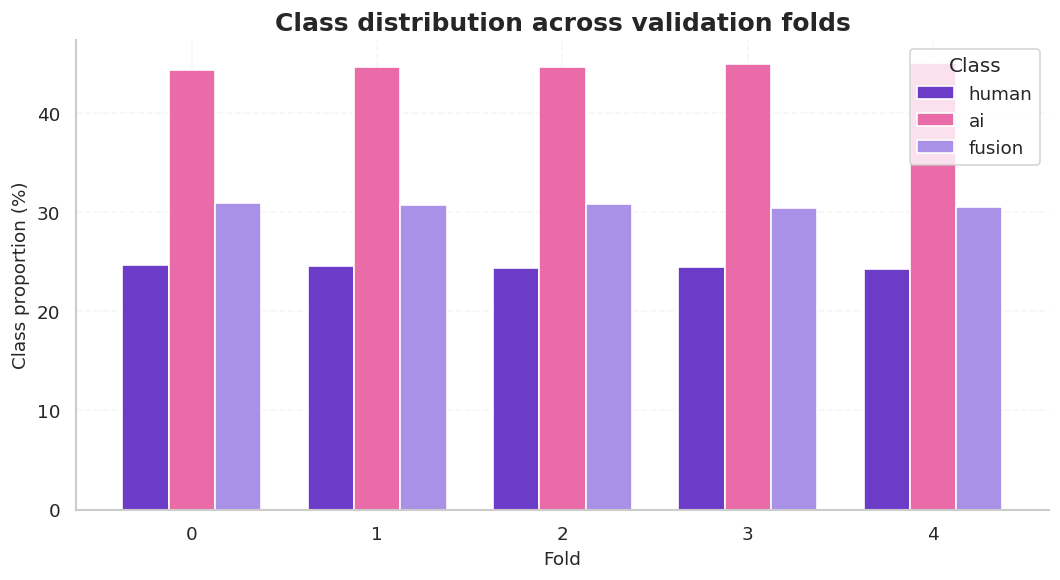

In [29]:
print("Language distribution across folds (%):")

language_balance = pd.crosstab(
    train_df["cv_fold"],
    train_df["lang"],
    normalize="index"
) * 100

display(language_balance.round(2))

print("\nDomain distribution across folds (%):")

domain_balance = pd.crosstab(
    train_df["cv_fold"],
    train_df["domain"],
    normalize="index"
) * 100

display(domain_balance.round(2))

fig, ax = plt.subplots(figsize=(9, 5))

fold_summary[class_order].plot(
    kind="bar",
    ax=ax,
    color=PALETTE,
    width=0.75
)

ax.set(
    title="Class distribution across validation folds",
    xlabel="Fold",
    ylabel="Class proportion (%)"
)

ax.tick_params(axis="x", rotation=0)
ax.legend(title="Class")
plt.tight_layout()
plt.show()


### Validation fold findings

The five group-aware folds contain between 53,741 and 55,302 documents. Class distributions remain consistent, with approximately 24.3–24.7% human, 44.4–45.2% AI, and 30.5–30.9% fusion examples.

Language and domain proportions are also similar across folds. No normalized-prefix fingerprint group appears in more than one fold.

These results indicate that the splitting strategy provides good distributional balance while preventing leakage through identical prefix fingerprints. However, the current groups do not necessarily capture all approximately similar documents, so I perform an additional cross-fold similarity audit before finalizing the validation strategy.


### Cross-fold near-duplicate audit

I evaluate whether the previously identified near-duplicate pairs are assigned to different validation folds.

Although identical prefix fingerprints are kept together, partially rewritten documents may have different prefixes despite substantial overlap elsewhere. Therefore, I use the verified MinHash pairs to identify potential leakage not captured by the current grouping strategy.

In [30]:
id_to_fold = train_df.set_index("id")["cv_fold"]

audit_df = similar_pairs_df.copy()

audit_df["fold_1"] = audit_df["id_1"].map(id_to_fold)
audit_df["fold_2"] = audit_df["id_2"].map(id_to_fold)

assert audit_df[["fold_1", "fold_2"]].notna().all().all()

audit_df["cross_fold"] = (
    audit_df["fold_1"] != audit_df["fold_2"]
)

total_pairs = len(audit_df)
cross_fold_pairs = int(audit_df["cross_fold"].sum())

print(f"Verified near-duplicate pairs: {total_pairs}")
print(f"Pairs assigned to different folds: {cross_fold_pairs}")

if total_pairs:
    print(f"Cross-fold rate: {cross_fold_pairs / total_pairs:.2%}")

print("\nCross-fold pairs by class combination:")
display(
    audit_df.groupby(
        ["label_1", "label_2"]
    )["cross_fold"]
    .agg(["count", "sum"])
    .rename(columns={
        "count": "Total pairs",
        "sum": "Cross-fold pairs"
    })
)

print("\nHighest-similarity cross-fold pairs:")
display(
    audit_df.loc[
        audit_df["cross_fold"],
        [
            "id_1", "id_2",
            "label_1", "label_2",
            "similarity", "fold_1", "fold_2"
        ]
    ]
    .sort_values("similarity", ascending=False)
    .head(15)
)

Verified near-duplicate pairs: 46
Pairs assigned to different folds: 12
Cross-fold rate: 26.09%

Cross-fold pairs by class combination:


Total pairs  Cross-fold pairs
label_1 label_2                               
fusion  fusion            15                 5
        human             13                 3
human   fusion            17                 4
        human              1                 0


Highest-similarity cross-fold pairs:


,id_1,id_2,label_1,label_2,similarity,fold_1,fold_2
23,1baca8,be8854,fusion,human,0.978587,0,3
12,364f9b,63a364,human,fusion,0.972093,1,4
17,6ac0c0,db0054,fusion,human,0.965116,4,2
45,3a076c,b141f9,human,fusion,0.933526,0,3
26,a36ca3,7ae290,human,fusion,0.904762,2,1
13,1c258e,22a9f3,fusion,fusion,0.887755,4,2
22,ca4fe5,6dd5ef,fusion,fusion,0.886000,2,0
7,18f672,703665,fusion,fusion,0.874251,1,0
3,756613,cbf429,human,fusion,0.846693,3,2
44,71d364,c2cfc0,fusion,fusion,0.828909,4,0



### Cross-fold similarity audit findings

The cross-fold audit identified 12 pairs assigned to different folds among 46 verified near-duplicate pairs (26.09%).

Several human–fusion pairs had Jaccard similarities above 0.96, indicating substantial overlap between documents placed on opposite sides of the validation split.

Therefore, normalized-prefix fingerprint grouping alone is insufficient. I will refine the document groups by combining fingerprint matches with verified near-duplicate relationships before generating the final cross-validation folds.


### Connected-component document grouping

I refine the document groups using a disjoint-set union (Union-Find) algorithm.

Documents are connected when they share a normalized-prefix fingerprint or belong to a previously verified near-duplicate pair. Transitive connections are merged into a single group, ensuring that all known related documents are assigned to the same validation fold.

This approach addresses the detected leakage cases while preserving reproducibility. However, the grouping remains approximate because near-duplicate retrieval was performed on a sample.

In [31]:
n = len(train_df)

parent = np.arange(n)
size = np.ones(n, dtype=np.int32)

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    root_a = find(a)
    root_b = find(b)

    if root_a == root_b:
        return

    if size[root_a] < size[root_b]:
        root_a, root_b = root_b, root_a

    parent[root_b] = root_a
    size[root_a] += size[root_b]

fingerprint_to_first = {}

for i, fp in enumerate(fingerprints):
    if fp in fingerprint_to_first:
        union(i, fingerprint_to_first[fp])
    else:
        fingerprint_to_first[fp] = i

id_to_position = {
    doc_id: i for i, doc_id in enumerate(train_df["id"])
}

for row in similar_pairs_df.itertuples(index=False):
    union(
        id_to_position[row.id_1],
        id_to_position[row.id_2]
    )

component_roots = np.array(
    [find(i) for i in range(n)]
)

train_df["group_id"] = pd.factorize(
    component_roots
)[0]

group_sizes = train_df["group_id"].value_counts()

print("Total document groups:", len(group_sizes))
print("Groups with multiple documents:", (group_sizes > 1).sum())
print("Largest group size:", group_sizes.max())
print("Documents in multi-document groups:", group_sizes[group_sizes > 1].sum())

Total document groups: 222768
Groups with multiple documents: 35015
Largest group size: 15
Documents in multi-document groups: 84599


In [32]:
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

new_folds = np.full(len(train_df), -1, dtype=np.int8)

for fold, (_, val_idx) in enumerate(
    sgkf.split(
        train_df,
        y=train_df["label"],
        groups=train_df["group_id"]
    )
):
    new_folds[val_idx] = fold

assert (new_folds >= 0).all()

train_df["cv_fold"] = new_folds

assert (
    train_df.groupby("group_id")["cv_fold"].nunique().max()
    == 1
)

id_to_fold = train_df.set_index("id")["cv_fold"]

cross_fold_count = sum(
    id_to_fold.loc[row.id_1] != id_to_fold.loc[row.id_2]
    for row in similar_pairs_df.itertuples(index=False)
)

print("Known cross-fold near-duplicate pairs:", cross_fold_count)

fold_balance = pd.crosstab(
    train_df["cv_fold"],
    train_df["label"],
    normalize="index"
).reindex(columns=class_order) * 100

fold_balance.insert(
    0,
    "Samples",
    train_df.groupby("cv_fold").size()
)

display(fold_balance.round(2))

Known cross-fold near-duplicate pairs: 0


label,Samples,human,ai,fusion
cv_fold,,,,
0,55031,24.58,44.92,30.50
1,54801,24.55,44.64,30.81
2,54569,24.42,44.71,30.87
3,53926,24.27,45.17,30.56
4,54025,24.68,44.43,30.89



### Final fold verification and export

I verify the updated fold assignments after merging known near-duplicate relationships. I check class, language, and domain distributions, ensure that connected document groups remain intact, and save the assignments for reproducible model comparisons.

The resulting folds protect against the known similarity relationships identified so far, but do not guarantee that all related source versions have been detected. I will use them as a fixed reference while considering additional full-dataset similarity checks.

In [33]:
assert train_df["cv_fold"].between(0, 4).all()
assert train_df["id"].is_unique
assert train_df.groupby("group_id")["cv_fold"].nunique().max() == 1

print("Language distribution by fold (%):")
display(
    (
        pd.crosstab(
            train_df["cv_fold"],
            train_df["lang"],
            normalize="index"
        ) * 100
    ).round(2)
)

print("\nDomain distribution by fold (%):")
display(
    (
        pd.crosstab(
            train_df["cv_fold"],
            train_df["domain"],
            normalize="index"
        ) * 100
    ).round(2)
)

print("\nLanguage × class balance per fold (%):")
display(
    (
        pd.crosstab(
            [train_df["cv_fold"], train_df["lang"]],
            train_df["label"],
            normalize="index"
        ).reindex(columns=class_order) * 100
    ).round(2)
)

print("\nAll group-integrity checks passed.")

Language distribution by fold (%):


lang,de-DE,en-EN
cv_fold,,
0,19.28,80.72
1,19.48,80.52
2,19.60,80.40
3,19.21,80.79
4,19.30,80.70



Domain distribution by fold (%):


domain,arxiv_papers,blog_authorship_corpus,bundestag,cnn_news,euro_court_cases,gutenberg,house_of_commons,student_essays
cv_fold,,,,,,,,
0,5.41,14.63,19.13,16.33,10.05,2.64,11.91,19.88
1,5.26,15.21,19.33,16.21,10.18,2.79,11.45,19.57
2,5.10,15.01,19.43,16.17,10.11,2.78,11.63,19.77
3,5.34,14.89,19.07,16.24,9.99,2.69,11.79,19.99
4,5.12,14.69,19.14,16.35,10.30,2.58,11.71,20.12



Language × class balance per fold (%):


label          human     ai  fusion
cv_fold lang                       
0       de-DE  27.46  39.29   33.25
        en-EN  23.90  46.26   29.84
1       de-DE  27.73  37.64   34.63
        en-EN  23.78  46.33   29.89
2       de-DE  27.44  37.97   34.59
        en-EN  23.68  46.36   29.96
3       de-DE  26.98  39.36   33.67
        en-EN  23.63  46.55   29.82
4       de-DE  27.86  38.46   33.68
        en-EN  23.92  45.86   30.22


All group-integrity checks passed.


In [34]:
from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/UCU_AI_HW3")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

fold_path = PROJECT_DIR / "cv_folds_v1.csv"

fold_export = train_df[
    ["id", "group_id", "cv_fold"]
].copy()

assert fold_export["id"].is_unique
assert len(fold_export) == 272352

fold_export.to_csv(fold_path, index=False)

saved_folds = pd.read_csv(fold_path, dtype={"id": str})

assert len(saved_folds) == len(train_df)
assert saved_folds["id"].equals(train_df["id"])

print("Saved:", fold_path)
print("Rows:", len(saved_folds))
print("Fold counts:")
display(saved_folds["cv_fold"].value_counts().sort_index())

Mounted at /content/drive
Saved: /content/drive/MyDrive/UCU_AI_HW3/cv_folds_v1.csv
Rows: 272352
Fold counts:


,count
cv_fold,
0,55031
1,54801
2,54569
3,53926
4,54025



## 8. Final data integrity and validation audit

I perform a final audit of the dataset and the saved group-aware cross-validation assignments before using them in subsequent experiments.

I verify that every training document has exactly one fold assignment, that related documents within the identified groups remain in the same fold, and that the validation split preserves class, language, and domain coverage.

I use fold 0 as the fixed validation set for all model comparisons. The grouping procedure mitigates known near-duplicate leakage, but it does not guarantee that every related document has been detected.


In [35]:
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

PROJECT_DIR = Path("/content/drive/MyDrive/UCU_AI_HW3")
FOLDS_PATH = PROJECT_DIR / "cv_folds_v1.csv"

assert FOLDS_PATH.exists(), "Saved CV folds not found."
assert "train_df" in globals(), "Load train.csv first."

folds = pd.read_csv(
    FOLDS_PATH,
    dtype={"id": str}
)

audit_df = train_df.drop(
    columns=["cv_fold", "group_id"],
    errors="ignore"
).copy()

audit_df["id"] = audit_df["id"].astype(str)

assert folds["id"].is_unique
assert len(folds) == len(audit_df)
assert audit_df["id"].is_unique
assert set(folds["id"]) == set(audit_df["id"])

audit_df = audit_df.merge(
    folds[["id", "group_id", "cv_fold"]],
    on="id",
    how="left",
    validate="one_to_one"
)

assert audit_df[["group_id", "cv_fold"]].notna().all().all()
assert audit_df["cv_fold"].between(0, 4).all()

groups_crossing_folds = (
    audit_df.groupby("group_id")["cv_fold"]
    .nunique()
    .gt(1)
    .sum()
)

assert groups_crossing_folds == 0

fold_counts = pd.crosstab(
    audit_df["cv_fold"],
    audit_df["label"]
).reindex(
    index=range(5),
    columns=["human", "ai", "fusion"],
    fill_value=0
)

fold_percentages = (
    fold_counts.div(fold_counts.sum(axis=1), axis=0)
    * 100
)

fold_summary = fold_counts.copy()
fold_summary["Total"] = fold_counts.sum(axis=1)

print("Dataset and fold integrity: PASSED")
print("Groups crossing folds:", groups_crossing_folds)

print("\nDocuments per fold:")
display(fold_summary)

print("\nClass distribution by fold (%):")
display(fold_percentages.round(2))

print("\nValidation fold 0:")
validation_df = audit_df[audit_df["cv_fold"] == 0]

print("Documents:", len(validation_df))
print(
    "Languages:",
    validation_df["lang"].value_counts().to_dict()
)
print(
    "Domains:",
    validation_df["domain"].nunique()
)

assert validation_df["label"].nunique() == 3
assert validation_df["lang"].nunique() == 2
assert validation_df["domain"].nunique() == 8

print("\nFinal EDA audit: PASSED")

Dataset and fold integrity: PASSED
Groups crossing folds: 0

Documents per fold:


label,human,ai,fusion,Total
cv_fold,,,,
0,13529,24718,16784,55031
1,13454,24461,16886,54801
2,13326,24399,16844,54569
3,13088,24357,16481,53926
4,13333,24005,16687,54025



Class distribution by fold (%):


label,human,ai,fusion
cv_fold,,,
0,24.58,44.92,30.50
1,24.55,44.64,30.81
2,24.42,44.71,30.87
3,24.27,45.17,30.56
4,24.68,44.43,30.89



Validation fold 0:
Documents: 55031
Languages: {'en-EN': 44420, 'de-DE': 10611}
Domains: 8

Final EDA audit: PASSED
